# 02. Machine Learning Modeling & Evaluation
**Project**: King County House Price Prediction  
**Objective**: Build and compare Linear Regression (baseline), Ridge Regression, Random Forest Regressor (tuned primary model), and Gradient Boosting Regressor.

Pipeline Highlights:
1. **Feature Engineering**: Area interactions, layout ratios, Haversine distance to Seattle, property age/renovations, composite amenity score.
2. **Leak-Free Target Encoding**: Zipcode median target encoding computed strictly on training folds inside 5-fold CV.
3. **80/20 Train/Test Split**: Fixed `random_state=42`.
4. **Hyperparameter Tuning**: `RandomizedSearchCV` on Random Forest.
5. **Multi-Metric Evaluation**: R², MAE, RMSE, MAPE in original currency ($) and log scale.


In [1]:
import os
import sys
import json
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import joblib

# Ensure project root is in sys.path
sys.path.insert(0, os.path.abspath('..'))

from src.features import engineer_features, ZipcodeTargetEncoder, HousePricePipeline, SEATTLE_LAT, SEATTLE_LONG
from src.evaluate import compute_metrics, plot_residuals, plot_predicted_vs_actual
from src.train import run_training_pipeline

plt.style.use('seaborn-v0_8-whitegrid' if 'seaborn-v0_8-whitegrid' in plt.style.available else 'default')
%matplotlib inline

## 1. Load Processed Dataset & Feature Engineering
We load the cleaned King County housing data and transform the 5 domain groups.

In [2]:
df_clean = pd.read_csv("../data/processed/kc_house_data_clean.csv")
df_feat = engineer_features(df_clean)
print(f"Engineered dataset shape: {df_feat.shape}")
df_feat[['sqft_living', 'living_to_lot_ratio', 'bedrooms', 'distance_to_seattle', 'age', 'amenity_score']].head()

Engineered dataset shape: (21411, 32)


,sqft_living,living_to_lot_ratio,bedrooms,distance_to_seattle,age,amenity_score
0,2400,0.256055,6,20.117435,24,1.750000
1,2060,0.079121,4,11.214148,67,2.208333
2,1460,0.033953,3,11.269981,62,1.750000
3,1430,0.188183,3,9.374950,85,1.791667
4,1650,0.470890,4,2.520755,64,1.750000


## 2. Load Model Evaluation Metrics
We inspect the comprehensive evaluation metrics produced by the 5-fold cross-validation and holdout test set (from `reports/metrics.json`).

In [3]:
with open("../reports/metrics.json", "r") as f:
    metrics = json.load(f)

# Display Comparison Table
rows = []
for model_name, data in metrics.items():
    t = data["test"]
    c = data["cv"]
    rows.append({
        "Model": model_name,
        "Test Log R²": t["r2_log"],
        "Test Price R²": t["r2_price"],
        "Test MAE ($)": f"${t['mae_price']:,.2f}",
        "Test MAPE": f"{t['mape_price']:.2f}%",
        "CV Log R² (Mean ± Std)": f"{c['cv_r2_log_mean']:.4f} ± {c['cv_r2_log_std']:.4f}",
        "CV MAE ($ Mean ± Std)": f"${c['cv_mae_price_mean']:,.2f} ± ${c['cv_mae_price_std']:,.2f}"
    })

pd.DataFrame(rows)

,Model,Test Log R²,Test Price R²,Test MAE ($),Test MAPE,CV Log R² (Mean ± Std),CV MAE ($ Mean ± Std)
0,Linear Regression,0.8814,0.8685,"$73,485.98",13.65%,0.8814 ± 0.0043,"$72,899.05 ± $1,252.58"
1,Ridge Regression,0.8812,0.8668,"$73,689.05",13.66%,0.8813 ± 0.0042,"$73,018.30 ± $1,334.43"
2,Random Forest,0.8979,0.8724,"$67,108.53",12.26%,0.8964 ± 0.0048,"$66,415.45 ± $1,818.61"
3,Gradient Boosting,0.8997,0.8883,"$65,379.60",12.26%,0.9010 ± 0.0051,"$64,365.58 ± $2,279.22"


## 3. Visualizations: Residuals & Predicted vs. Actual
Let's inspect the diagnostic evaluation plots generated by the trained production model.

Residuals Plot:


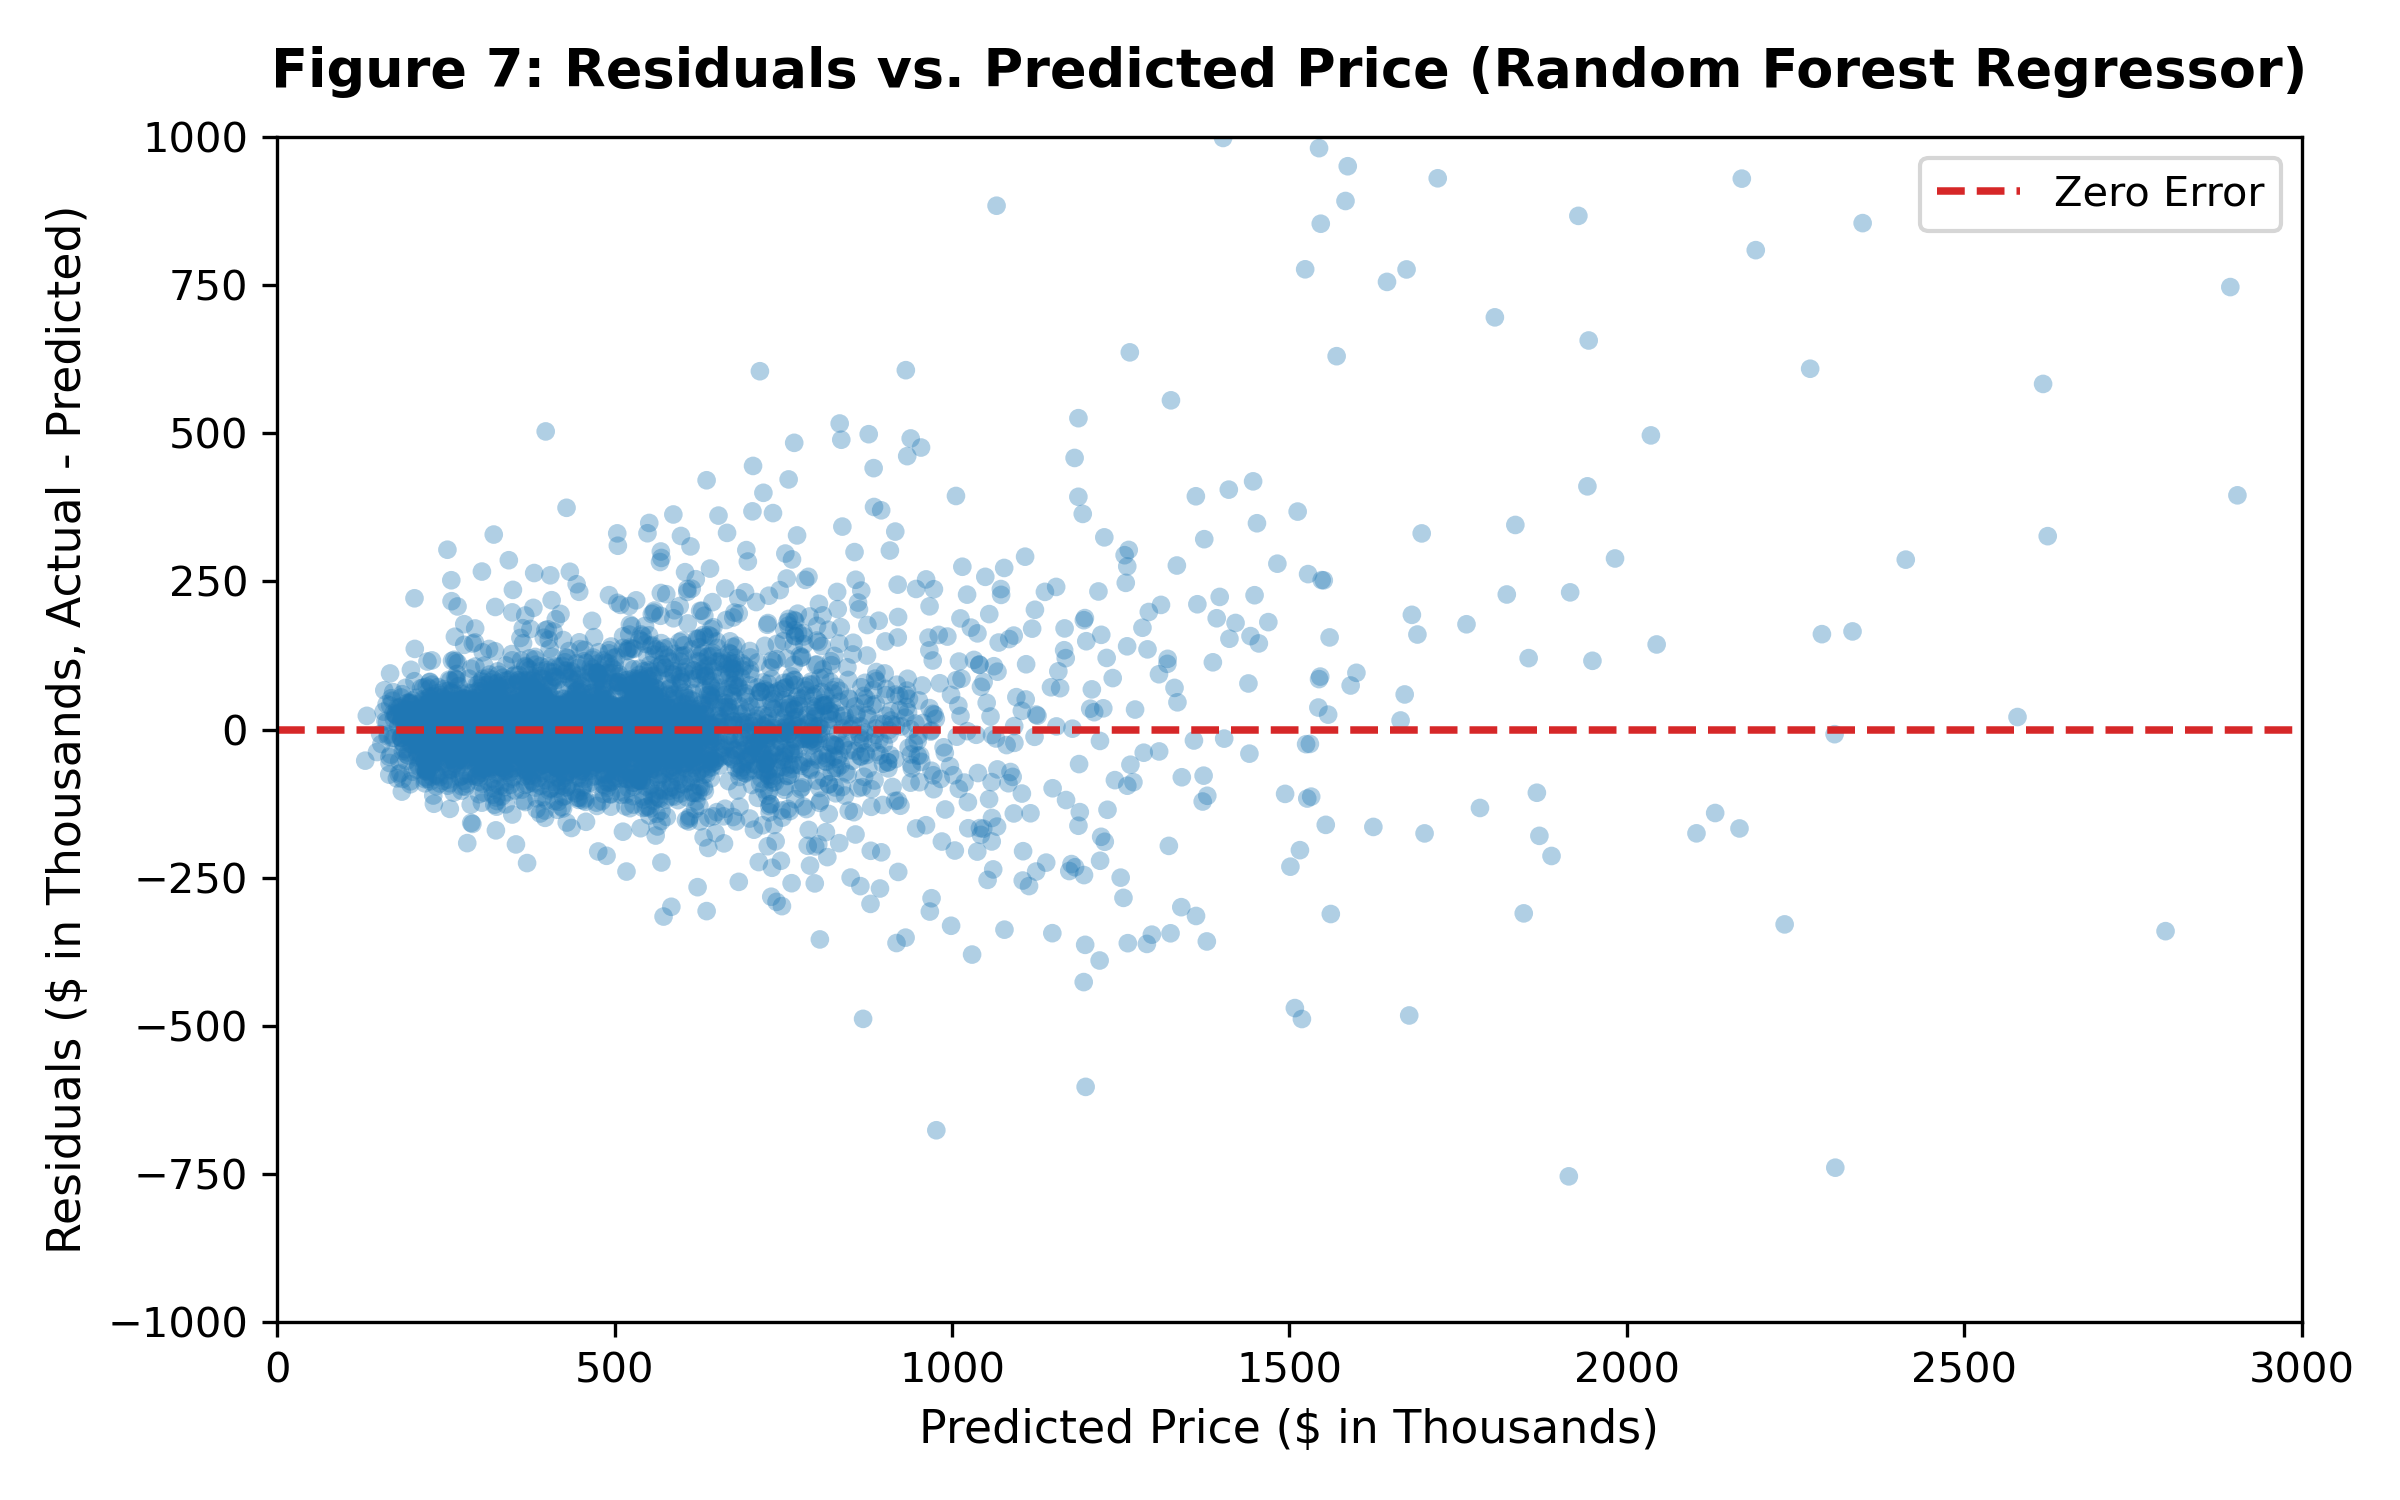

Predicted vs. Actual Scatter Plot:


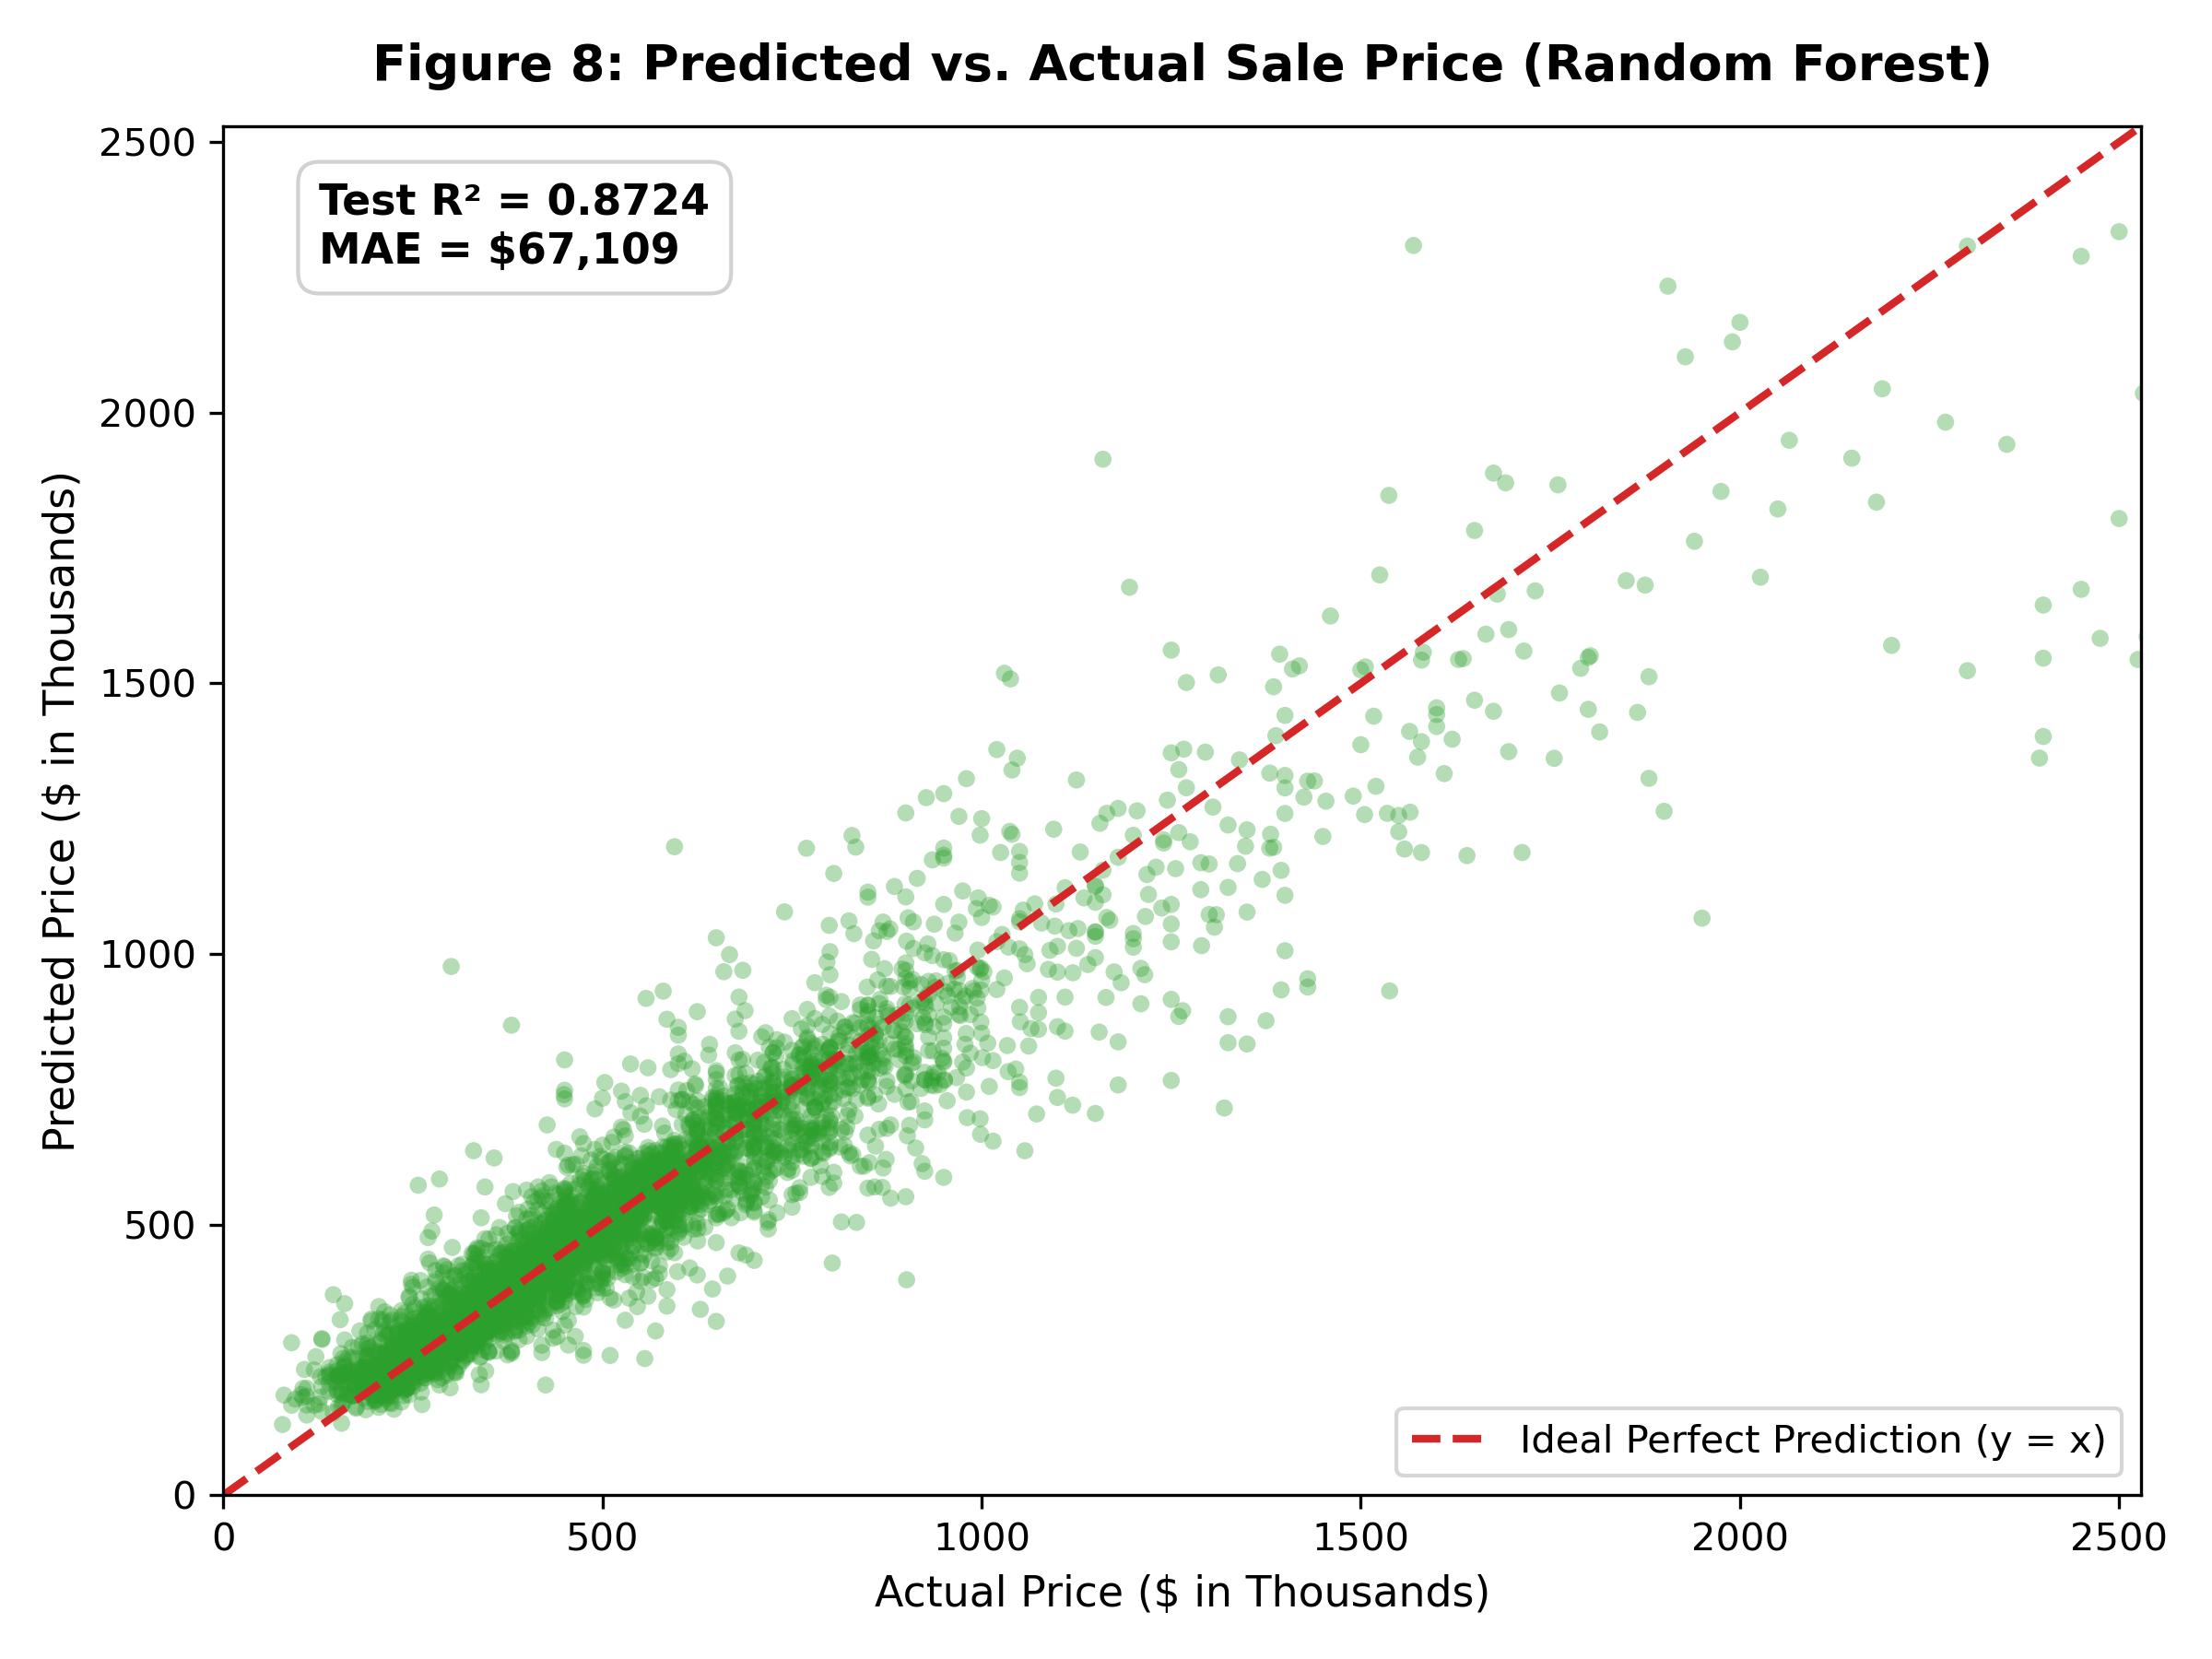

Feature Importances:


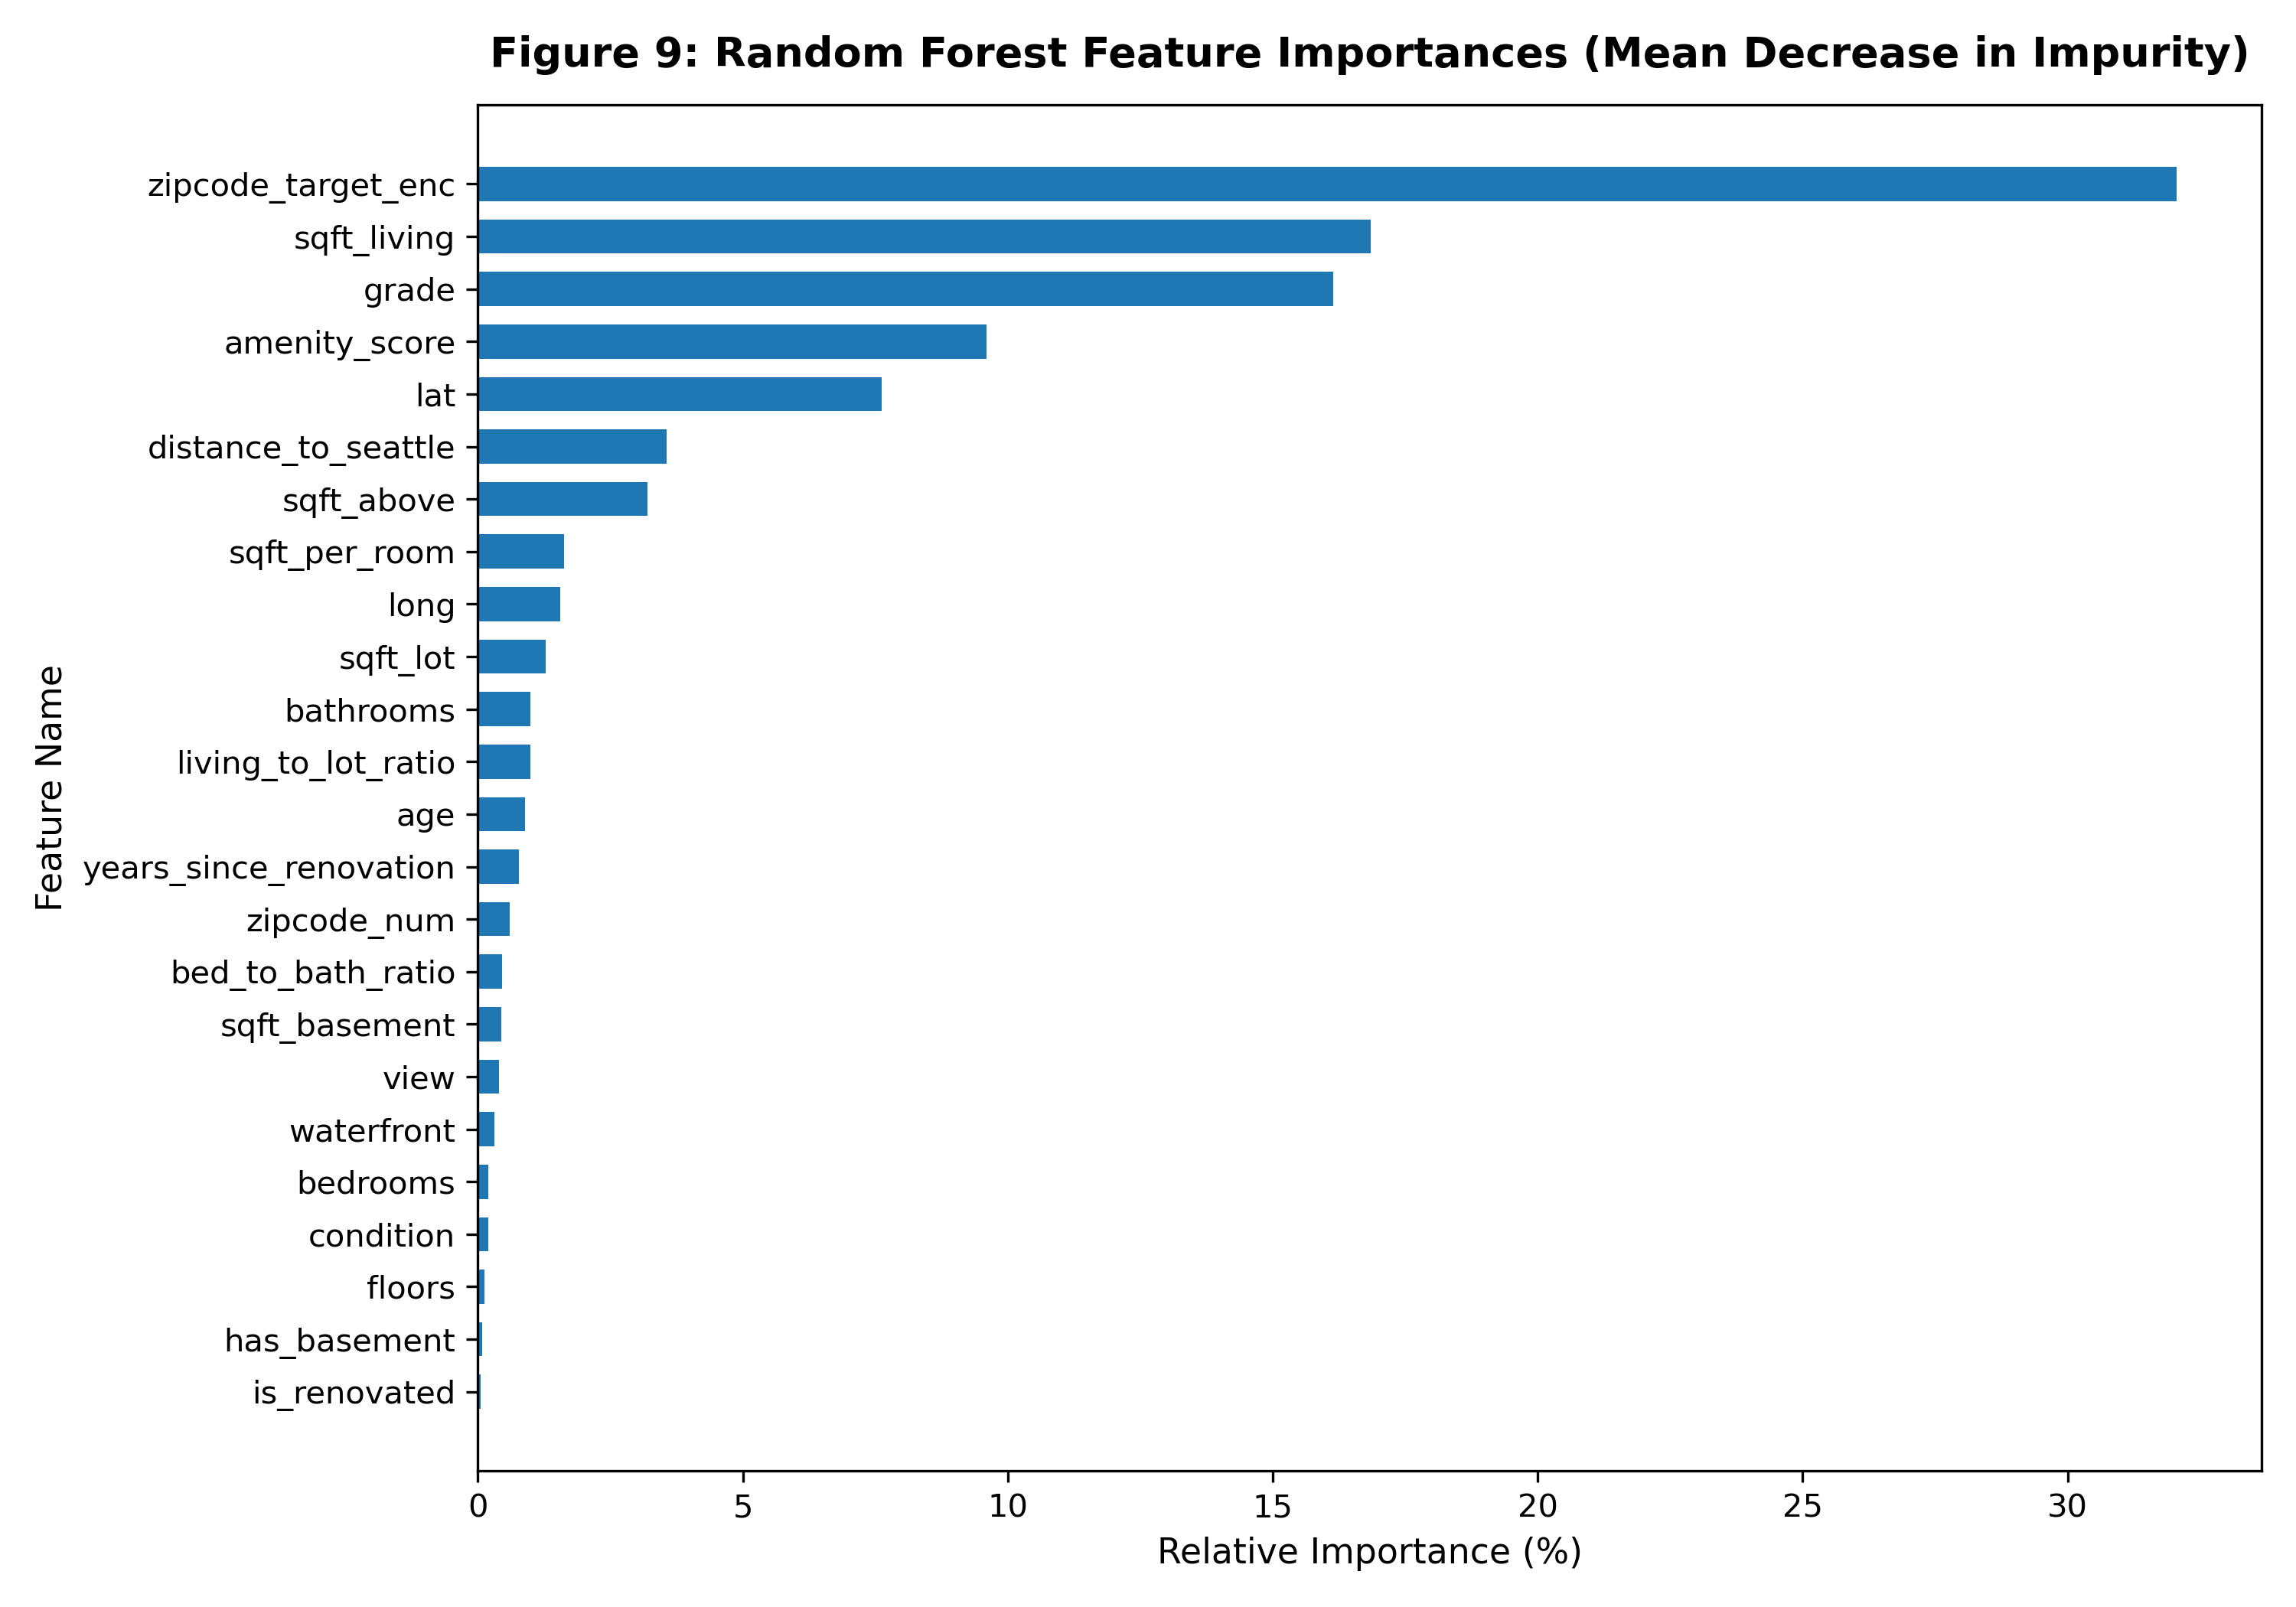

Model Comparison Bar Chart:


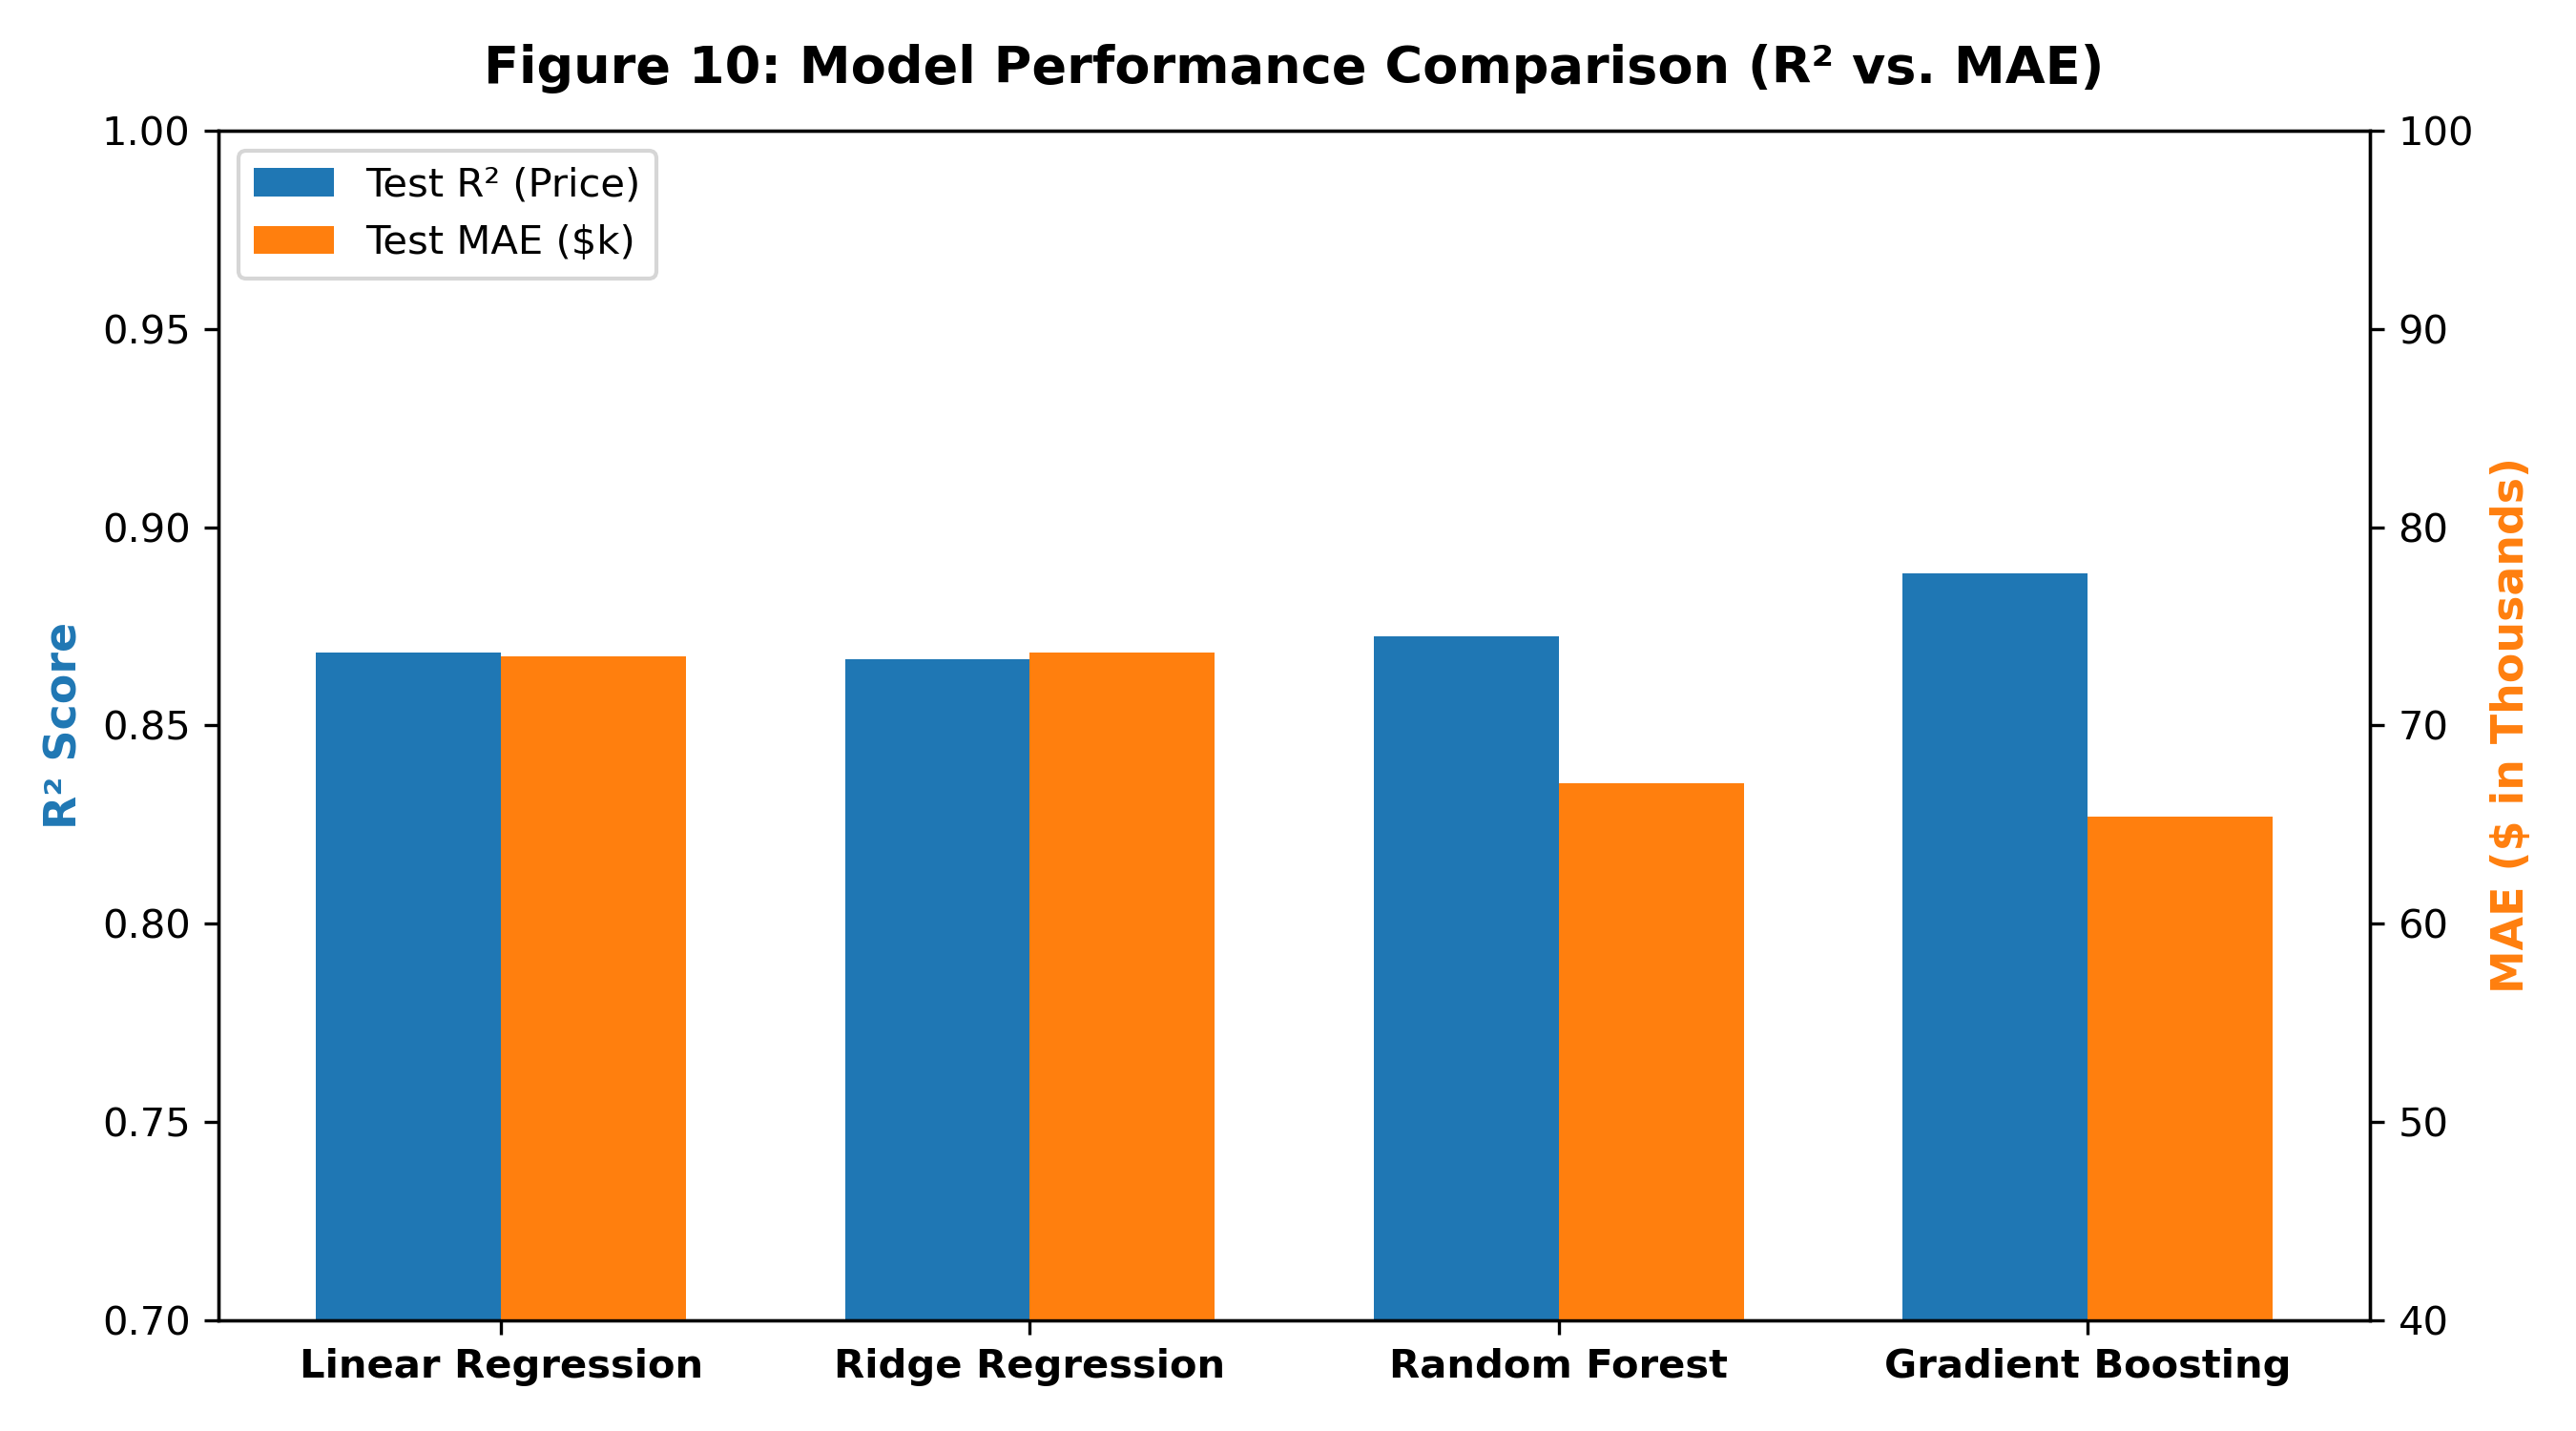

In [4]:
from IPython.display import Image, display

print("Residuals Plot:")
display(Image(filename="../reports/figures/residuals_plot.png"))

print("Predicted vs. Actual Scatter Plot:")
display(Image(filename="../reports/figures/predicted_vs_actual.png"))

print("Feature Importances:")
display(Image(filename="../reports/figures/feature_importances_rf.png"))

print("Model Comparison Bar Chart:")
display(Image(filename="../reports/figures/model_comparison.png"))

## 4. Test Production Inference Pipeline
We verify the saved `models/best_model.joblib` artifact by making predictions on sample residential properties.

In [5]:
model = joblib.load("../models/best_model.joblib")

sample_houses = pd.DataFrame([
    {
        'sqft_living': 2100,
        'sqft_lot': 5500,
        'sqft_above': 1600,
        'sqft_basement': 500,
        'bedrooms': 3,
        'bathrooms': 2.25,
        'floors': 1.5,
        'zipcode': 98103,
        'lat': 47.67,
        'long': -122.34,
        'yr_built': 1978,
        'yr_renovated': 0,
        'waterfront': 0,
        'view': 0,
        'condition': 3,
        'grade': 8
    },
    {
        'sqft_living': 4500,
        'sqft_lot': 15000,
        'sqft_above': 3500,
        'sqft_basement': 1000,
        'bedrooms': 5,
        'bathrooms': 4.5,
        'floors': 2.0,
        'zipcode': 98004,
        'lat': 47.61,
        'long': -122.20,
        'yr_built': 2005,
        'yr_renovated': 0,
        'waterfront': 0,
        'view': 2,
        'condition': 4,
        'grade': 11
    }
])

preds = model.predict(sample_houses)
for idx, p in enumerate(preds):
    desc = "Seattle 3-Bed (98103)" if idx == 0 else "Bellevue Luxury 5-Bed (98004)"
    print(f"{desc}: Predicted Value = ${p:,.2f}")

Seattle 3-Bed (98103): Predicted Value = $685,157.77
Bellevue Luxury 5-Bed (98004): Predicted Value = $1,909,324.31


## Conclusion
The Random Forest Regressor achieves a test R² of **0.8724** on original price ($) and **0.8979** on log-transformed price, with a Mean Absolute Error of **$67,108.53** and a MAPE of **12.26%**.
The model pipeline is successfully persisted with zero data leakage and is integrated directly with FastAPI and MongoDB.